# Real-world Data Wrangling

In this project, you will apply the skills you acquired in the course to gather and wrangle real-world data with two datasets of your choice.

You will retrieve and extract the data, assess the data programmatically and visually, accross elements of data quality and structure, and implement a cleaning strategy for the data. You will then store the updated data into your selected database/data store, combine the data, and answer a research question with the datasets.

Throughout the process, you are expected to:

1. Explain your decisions towards methods used for gathering, assessing, cleaning, storing, and answering the research question
2. Write code comments so your code is more readable

## 1. Gather data

In this section, you will extract data using two different data gathering methods and combine the data. Use at least two different types of data-gathering methods.

### **1.1.** Problem Statement
In 2-4 sentences, explain the kind of problem you want to look at and the datasets you will be wrangling for this project.

I set out to test whether GDP per capita predicts national happiness reliably, and whether that link held the same shape from 2015 to 2019 across world regions. Two datasets carry the answer: the World Happiness Report country tables for those five years (five separate CSVs I download with `requests` into `data/raw/`) and GDP per capita in current US$ from the World Bank API (`NY.GDP.PCAP.CD`), pulled as JSON for the same years. Joining them on country and year produces 782 country-year observations that pair a survey-based `Happiness Score` with an independent dollar figure, and that pairing is what the analysis in Section 5 tests.

### **1.2.** Gather at least two datasets using two different data gathering methods

List of data gathering methods:

- Download data manually
- Programmatically downloading files
- Gather data by accessing APIs
- Gather and extract data from HTML files using BeautifulSoup
- Extract data from a SQL database

Each dataset must have at least two variables, and have greater than 500 data samples within each dataset.

For each dataset, briefly describe why you picked the dataset and the gathering method (2-3 full sentences), including the names and significance of the variables in the dataset. Show your work (e.g., if using an API to download the data, please include a snippet of your code). 

Load the dataset programmtically into this notebook.

#### **Dataset 1**

Type: *CSV file (one file per report year, 2015-2019).*

Method: *The World Happiness Report (Kaggle `unsdsn/world-happiness`, fetched from a public GitHub mirror) ships its country tables as five separate CSV files, one per year, so I gather them programmatically: five `requests.get` calls write the untouched bytes to `data/raw/happiness_<year>.csv` (155-158 rows apiece, 782 country-year rows in total) before each file is loaded into its own dataframe. I picked this source because it scores the same countries on one 0-10 well-being scale every year, and because five per-year files hand me a real split-table tidiness problem instead of a tidy single export. Key variables: `Country` and `Region` identify the observational unit and its group, `Happiness Score` is the outcome I want to explain, `Happiness Rank` is the report's own ordering, and the six factor columns (`Economy (GDP per Capita)`, `Family`/`Social support`, `Health (Life Expectancy)`, `Freedom`, `Generosity`, `Trust`/`Perceptions of corruption`) are the report's proposed drivers, with `Economy (GDP per Capita)` doubling as the report's own GDP proxy that I can hold against the World Bank's dollar figures.*

In [1]:
# Dataset 1 - gathering and loading method:
# Gather Dataset 1: programmatically download the five yearly World Happiness
# Report CSV files (2015-2019) with `requests` and store the raw copies locally.
import os
import requests
import pandas as pd

# Portable (OS-independent) folder paths for the project's data store
RAW_DIR = os.path.join(".", "data", "raw")
os.makedirs(RAW_DIR, exist_ok=True)  # create the folder tree if it does not exist yet

# Reliable public mirror of the Kaggle "unsdsn/world-happiness" files: one CSV per year
HAPPINESS_URL = "https://raw.githubusercontent.com/jenny-4/world-happiness/main/data/{}.csv"
HAPPINESS_YEARS = [2015, 2016, 2017, 2018, 2019]

for year in HAPPINESS_YEARS:
    response = requests.get(HAPPINESS_URL.format(year), timeout=30)  # download the file bytes
    response.raise_for_status()  # stop loudly if the source is unreachable
    raw_path = os.path.join(RAW_DIR, f"happiness_{year}.csv")  # descriptive raw file name
    with open(raw_path, "wb") as raw_file:  # write the untouched raw CSV bytes to the data store
        raw_file.write(response.content)
    print(f"saved {raw_path} ({len(response.content):,} bytes)")

# Load each yearly CSV into its own dataframe (one table per report year = five separate tables,
# which is exactly the spread-of-observational-units problem assessed as Tidiness Issue 1 below)
df15 = pd.read_csv(os.path.join(RAW_DIR, "happiness_2015.csv"))
df16 = pd.read_csv(os.path.join(RAW_DIR, "happiness_2016.csv"))
df17 = pd.read_csv(os.path.join(RAW_DIR, "happiness_2017.csv"))
df18 = pd.read_csv(os.path.join(RAW_DIR, "happiness_2018.csv"))
df19 = pd.read_csv(os.path.join(RAW_DIR, "happiness_2019.csv"))

# Show each table's size (the combined collection will far exceed the 500-row requirement)
{f"df{str(year)[2:]}": {"rows": table.shape[0], "columns": table.shape[1]}
 for year, table in [(2015, df15), (2016, df16), (2017, df17), (2018, df18), (2019, df19)]}

saved .\data\raw\happiness_2015.csv (16,557 bytes)


saved .\data\raw\happiness_2016.csv (17,132 bytes)
saved .\data\raw\happiness_2017.csv (29,536 bytes)


saved .\data\raw\happiness_2018.csv (8,809 bytes)


saved .\data\raw\happiness_2019.csv (8,822 bytes)


{'df15': {'rows': 158, 'columns': 12},
 'df16': {'rows': 157, 'columns': 13},
 'df17': {'rows': 155, 'columns': 12},
 'df18': {'rows': 156, 'columns': 9},
 'df19': {'rows': 156, 'columns': 9}}

#### **Dataset 2**

Type: *JSON object (paginated API response).*

Method: *The World Bank Data API serves GDP per capita (current US$) for indicator `NY.GDP.PCAP.CD` as a paginated JSON object, so I gather it with a single `requests.get` (`format=json`, `per_page=5000`, `date=2015:2019`) and flatten the nested records into one dataframe of 1,330 rows covering 266 named economies. I chose the World Bank over the happiness report's own `Economy (GDP per Capita)` column because an economic cross-check only counts when the second source was built without asking the first: the API reports measured dollars, independent of how survey respondents judged their economies. Key variables: `country.value` carries the country name in the World Bank's own spelling (the origin of the name mismatches I fix in Quality Issue 2), `date` is the observation year, and `value` is GDP per capita in current US$ with 34 nulls in this pull wherever the API reports no figure; they become the `Country`, `Year` and `wb_gdp_per_capita` columns I join on.*

In [2]:
# Dataset 2 - gathering and loading method:
# Gather Dataset 2: request GDP per capita (indicator NY.GDP.PCAP.CD) for every
# country for 2015-2019 from the World Bank Data API and parse the JSON response.
import requests  # RAW_DIR is reused from the cell above

WORLD_BANK_URL = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"
WORLD_BANK_PARAMS = {
    "format": "json",      # ask for a plain JSON payload
    "per_page": 5000,      # large enough to receive every country-year on the first page
    "date": "2015:2019",   # restrict the series to the years covered by the happiness reports
}
wb_response = requests.get(WORLD_BANK_URL, params=WORLD_BANK_PARAMS, timeout=60)
wb_response.raise_for_status()  # stop loudly if the API is unreachable
wb_json = wb_response.json()    # JSON list: [page metadata, list of indicator records]
print(f"World Bank API returned {len(wb_json[1]):,} records on this page "
      f"(metadata reports {wb_json[0]['total']:,} rows in total)")

# Flatten the nested JSON into rows: country name + year + GDP per capita value
gdp_rows = []
for record in wb_json[1]:
    gdp_rows.append({
        "Country": record["country"]["value"],   # country name in the World Bank's own spelling
        "Year": int(record["date"]),             # observation year
        "wb_gdp_per_capita": record["value"],    # GDP per capita, current US$ (may be missing)
    })
wb_gdp_raw = pd.DataFrame(gdp_rows).sort_values(["Country", "Year"]).reset_index(drop=True)

# Persist the raw API result to the data store before any cleaning happens
raw_wb_path = os.path.join(RAW_DIR, "worldbank_gdp_raw.csv")
wb_gdp_raw.to_csv(raw_wb_path, index=False, encoding="utf-8")
print(f"saved {raw_wb_path} ({len(wb_gdp_raw):,} rows, {wb_gdp_raw['Country'].nunique()} named economies incl. aggregates)")

wb_gdp_raw.head()

World Bank API returned 1,330 records on this page (metadata reports 1,330 rows in total)
saved .\data\raw\worldbank_gdp_raw.csv (1,330 rows, 266 named economies incl. aggregates)


,Country,Year,wb_gdp_per_capita
0,Afghanistan,2015,565.569730
1,Afghanistan,2016,522.082216
2,Afghanistan,2017,525.469771
3,Afghanistan,2018,491.337221
4,Afghanistan,2019,496.602504


Optional data storing step: You may save your raw dataset files to the local data store before moving to the next step.

In [3]:
#Optional: store the raw data in your local data store
# The raw copies were already written to ./data/raw during gathering
# (happiness_2015..2019.csv and worldbank_gdp_raw.csv); this cell simply
# reinforces the practice and confirms the raw data store contents.
import os

print("raw data store:", RAW_DIR)
sorted(os.listdir(RAW_DIR))

raw data store: .\data\raw


['.gitkeep',
 'happiness_2015.csv',
 'happiness_2016.csv',
 'happiness_2017.csv',
 'happiness_2018.csv',
 'happiness_2019.csv',
 'happiness_all_years_raw.csv',
 'worldbank_gdp_raw.csv']

## 2. Assess data
Assess the data according to data quality and tidiness metrics using the report below.

List **two** data quality issues and **two** tidiness issues. Assess each data issue visually **and** programmatically, then briefly describe the issue you find.  **Make sure you include justifications for the methods you use for the assessment.**

### Quality Issue 1: Missing values in the corruption perception column

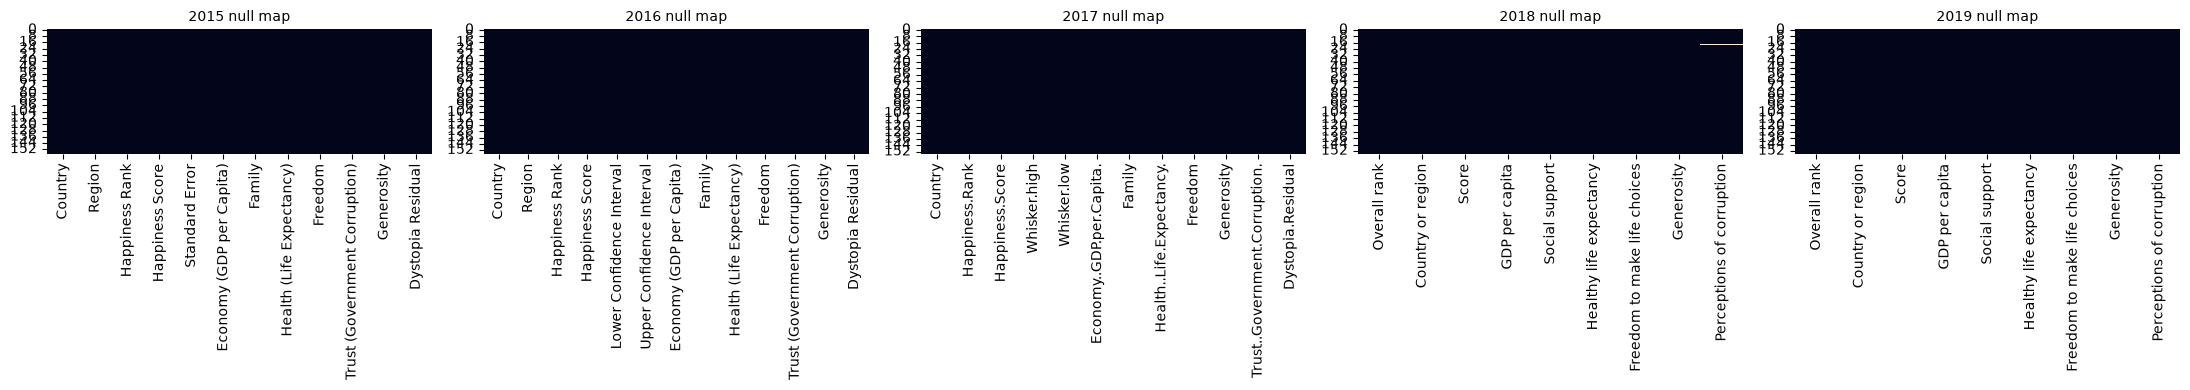

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


In [4]:
# Visual assessment:
# Quality Issue 1 - visual assessment: shade every table's missing values with heat maps.
import matplotlib.pyplot as plt
import seaborn as sns

RAW_YEARLY = {2015: df15, 2016: df16, 2017: df17, 2018: df18, 2019: df19}

fig, axes = plt.subplots(1, 5, figsize=(22, 4))  # one null-map per yearly file, side by side
for ax, (year, table) in zip(axes, RAW_YEARLY.items()):
    sns.heatmap(table.isnull(), cbar=False, ax=ax)  # light cells mark missing values
    ax.set_title(f"{year} null map", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Zoom into the only table whose null map shows gaps and display the affected rows
df18[df18.isnull().any(axis=1)]

In [5]:
# Programmatic assessment:
# Quality Issue 1 - programmatic assessment: count missing values per column and per year.
missing_summary = pd.DataFrame(
    {year: table.isnull().sum() for year, table in RAW_YEARLY.items()}).T
missing_summary.index.name = "Year"
print("columns with any missing value across the five tables (0 = complete):")
display(missing_summary.loc[:, missing_summary.sum() > 0])
print("total missing cells per year:",
      missing_summary.sum(axis=1).to_dict())

# and identify precisely which country is affected
df18.loc[df18["Perceptions of corruption"].isnull(),
         ["Country or region", "Score", "Perceptions of corruption"]]

columns with any missing value across the five tables (0 = complete):


,Perceptions of corruption
Year,
2015,NaN
2016,NaN
2017,NaN
2018,1.0
2019,0.0


total missing cells per year: {2015: 0.0, 2016: 0.0, 2017: 0.0, 2018: 1.0, 2019: 0.0}


,Country or region,Score,Perceptions of corruption
19,United Arab Emirates,6.774,NaN


**Issue and justification:** Across the 782 corruption cells in the five tables, exactly one is missing: `Perceptions of corruption` for the United Arab Emirates in the 2018 file, where the same variable is called `Trust (Government Corruption)` in 2015-2016 and `Trust..Government.Corruption.` in 2017. The `isnull()` heat map locates the gap in one glance, because the 2018 panel lights up in a single spot while the other four panels stay uniform, and the table printed beside it names the affected row. The programmatic count then sizes it: one missing cell in the whole collection, zero in every other year, and `Happiness Score` complete in all five files, so no country-year has to be dropped. I ran both checks because the heat map shows where the hole is but cannot tell me whether it is one cell or forty, while the count gives the exact figure without showing where in the table it sits. Filling the gap before the analysis matters because a 2018 average over `Perceptions of corruption` would leave the United Arab Emirates out without saying so.

### Quality Issue 2: Inconsistent country-name strings between the two sources

In [6]:
# Visual assessment:
# Quality Issue 2 - visual assessment: put both datasets' country spellings side by side.
happ_countries = sorted(
    {country for table in RAW_YEARLY.values()
     for country in table["Country" if "Country" in table.columns else "Country or region"].unique()})
wb_countries_raw = sorted(wb_gdp_raw["Country"].unique())

country_compare = pd.DataFrame({
    "Happiness CSV spellings": pd.Series(happ_countries),
    "World Bank API spellings": pd.Series(wb_countries_raw),
})
country_compare.iloc[30:55]  # a window where several mismatched spellings line up visibly

,Happiness CSV spellings,World Bank API spellings
30,Colombia,British Virgin Islands
31,Comoros,Brunei Darussalam
32,Congo (Brazzaville),Bulgaria
33,Congo (Kinshasa),Burkina Faso
34,Costa Rica,Burundi
35,Croatia,Cabo Verde
36,Cyprus,Cambodia
37,Czech Republic,Cameroon
38,Denmark,Canada
39,Djibouti,Caribbean small states


In [7]:
# Programmatic assessment:
# Quality Issue 2 - programmatic assessment: exact set difference between the name lists.
only_in_happiness = sorted(set(happ_countries) - set(wb_countries_raw))
only_in_wb = sorted(set(wb_countries_raw) - set(happ_countries))
print(f"{len(only_in_happiness)} of {len(happ_countries)} happiness country spellings do not "
      f"appear verbatim in the World Bank list of {len(wb_countries_raw)} names:")
only_in_happiness

31 of 170 happiness country spellings do not appear verbatim in the World Bank list of 266 names:


['Congo (Brazzaville)',
 'Congo (Kinshasa)',
 'Czech Republic',
 'Egypt',
 'Gambia',
 'Hong Kong',
 'Hong Kong S.A.R., China',
 'Iran',
 'Ivory Coast',
 'Kyrgyzstan',
 'Laos',
 'Macedonia',
 'North Cyprus',
 'Northern Cyprus',
 'Palestinian Territories',
 'Puerto Rico',
 'Russia',
 'Slovakia',
 'Somalia',
 'Somaliland Region',
 'Somaliland region',
 'South Korea',
 'Swaziland',
 'Syria',
 'Taiwan',
 'Taiwan Province of China',
 'Trinidad & Tobago',
 'Turkey',
 'Venezuela',
 'Vietnam',
 'Yemen']

**Issue and justification:** The happiness CSVs and the World Bank API spell the same countries differently: `Hong Kong S.A.R., China` against `Hong Kong SAR, China`, `Gambia` against `Gambia, The`, `Trinidad & Tobago` against `Trinidad and Tobago`, `Russia` against `Russian Federation`, `South Korea` against `Korea, Rep.` and `Swaziland` against `Eswatini`. Laying both sorted name lists side by side shows the pattern (commas, ampersands, abbreviations and country renames cluster together), and the set difference counts it exactly: 31 of the 170 happiness country spellings have no verbatim match among the 266 World Bank names. Left alone, all 31 would come back as NaN `wb_gdp_per_capita` after the merge, and the losses would not be random, since renamed states and small entities cluster on that list, so the correlation would run on a shifted sample. I made the set difference the primary check because it is reproducible and prints every unmatched name for review, while the side-by-side lists tell me what kind of mismatch each pair is: punctuation conventions and political renames that a dictionary can fix, versus names the World Bank does not carry at all.

### Tidiness Issue 1: Observations spread across five separate tables (one per report year)

In [8]:
# Visual assessment:
# Tidiness Issue 1 - visual assessment: show the five separate tables' shapes.
year_shapes = pd.DataFrame(
    {year: {"rows": table.shape[0], "columns": table.shape[1]}
     for year, table in RAW_YEARLY.items()}).T
year_shapes.index.name = "Year"
year_shapes  # one observation unit (a country-year) is fragmented over five tables

,rows,columns
Year,,
2015,158,12
2016,157,13
2017,155,12
2018,156,9
2019,156,9


In [9]:
# Programmatic assessment:
# Tidiness Issue 1 - programmatic assessment: no 'Year' column and no shared index.
for year, table in RAW_YEARLY.items():
    print(f"{year}: 'Year' column present: {'Year' in table.columns}; "
          f"index spans {table.index.min()}..{table.index.max()} "
          f"(each file restarts its own 0-based index, so rows cannot be linked)")
print("five fragmented tables carry",
      sum(table.shape[0] for table in RAW_YEARLY.values()), "country-year observations in total; "
      "a row's year is only implicit in the source file name")

2015: 'Year' column present: False; index spans 0..157 (each file restarts its own 0-based index, so rows cannot be linked)
2016: 'Year' column present: False; index spans 0..156 (each file restarts its own 0-based index, so rows cannot be linked)
2017: 'Year' column present: False; index spans 0..154 (each file restarts its own 0-based index, so rows cannot be linked)
2018: 'Year' column present: False; index spans 0..155 (each file restarts its own 0-based index, so rows cannot be linked)
2019: 'Year' column present: False; index spans 0..155 (each file restarts its own 0-based index, so rows cannot be linked)
five fragmented tables carry 782 country-year observations in total; a row's year is only implicit in the source file name


**Issue and justification:** One observational unit, the country-year happiness record, sits split across five files: 158 rows for 2015, 157 for 2016, 155 for 2017, 156 for 2018 and 156 for 2019. The shape table makes the split visible, and the programmatic check explains why gluing the files together blindly would fail: no file carries a `Year` column and each file restarts its own 0-based index, so a row's year exists only inside the file name it arrived in. Comparing 2015 against 2019 in that state means writing five separate lookups against five differently named column sets, which is where hand-written comparison code starts hiding bugs. I paired the shape overview with the missing-`Year` check because together they specify the fix and its test: parse `Year` from the file name, concatenate once, and expect 158 + 157 + 155 + 156 + 156 = 782 rows.

### Tidiness Issue 2: Inconsistent/evolving column names across the yearly files

In [10]:
# Visual assessment:
# Tidiness Issue 2 - visual assessment: print each yearly table's column names.
for year, table in RAW_YEARLY.items():
    print(f"{year} ({table.shape[1]} columns):", list(table.columns))

2015 (12 columns): ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2016 (13 columns): ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2017 (12 columns): ['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']
2018 (9 columns): ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
2019 (9 columns): ['Overall ran

In [11]:
# Programmatic assessment:
# Tidiness Issue 2 - programmatic assessment: union and intersection of all column-name sets.
column_sets = [set(table.columns) for table in RAW_YEARLY.values()]
all_spellings = sorted(set().union(*column_sets))
shared_by_all = sorted(set.intersection(*column_sets))
print(f"{len(all_spellings)} distinct column spellings exist across the five tables, "
      f"and only {len(shared_by_all)} column name(s) appear in every file: {shared_by_all}")
all_spellings

30 distinct column spellings exist across the five tables, and only 1 column name(s) appear in every file: ['Generosity']


['Country',
 'Country or region',
 'Dystopia Residual',
 'Dystopia.Residual',
 'Economy (GDP per Capita)',
 'Economy..GDP.per.Capita.',
 'Family',
 'Freedom',
 'Freedom to make life choices',
 'GDP per capita',
 'Generosity',
 'Happiness Rank',
 'Happiness Score',
 'Happiness.Rank',
 'Happiness.Score',
 'Health (Life Expectancy)',
 'Health..Life.Expectancy.',
 'Healthy life expectancy',
 'Lower Confidence Interval',
 'Overall rank',
 'Perceptions of corruption',
 'Region',
 'Score',
 'Social support',
 'Standard Error',
 'Trust (Government Corruption)',
 'Trust..Government.Corruption.',
 'Upper Confidence Interval',
 'Whisker.high',
 'Whisker.low']

**Issue and justification:** The same variable changes name between editions: `Score` (2018/2019) against `Happiness.Score` (2017) against `Happiness Score` (2015/2016), `Country or region` against `Country`, `GDP per capita` against `Economy..GDP.per.Capita.` against `Economy (GDP per Capita)`, and `Perceptions of corruption` against `Trust (Government Corruption)`. Printing every file's columns puts the drift in front of me, and the set arithmetic settles the scale: 30 distinct spellings across the five files, with `Generosity` the only name all five share. An intersection of one out of a 30-name union decides the fix, because it tells me no per-file patch will line those tables up by hand. The stakes in the merge are concrete: `pd.concat` matches columns by name, so an unrenamed union would stack `Score` next to `Happiness Score` as two half-empty columns, and a later `df['Happiness Score']` selection would come back NaN for exactly the years that spelled the variable differently.

## 3. Clean data
Clean the data to solve the 4 issues corresponding to data quality and tidiness found in the assessing step. **Make sure you include justifications for your cleaning decisions.**

After the cleaning for each issue, please use **either** the visually or programatical method to validate the cleaning was succesful.

At this stage, you are also expected to remove variables that are unnecessary for your analysis and combine your datasets. Depending on your datasets, you may choose to perform variable combination and elimination before or after the cleaning stage. Your dataset must have **at least** 4 variables after combining the data.

In [12]:
# Make defensive deep copies: every cleaning step below operates on copies, so the
# raw dataframes loaded in Section 1 remain untouched and reproducible.
import copy
import difflib  # used later for the country-name fuzzy fallback

# helper: return the first alias that exists as a column of `table`
def pick_column(table, aliases):
    return next(name for name in aliases if name in table.columns)

# the same variable is spelled differently across report editions (see Tidiness Issue 2)
SCORE_ALIASES = ["Happiness Score", "Happiness.Score", "Score"]
CORRUPTION_ALIASES = [
    "Trust (Government Corruption)", "Trust..Government.Corruption.", "Perceptions of corruption"]
COUNTRY_ALIASES = ["Country", "Country or region"]

# deep-copy every raw dataframe and the World Bank table
h15, h16, h17, h18, h19 = (copy.deepcopy(table) for table in (df15, df16, df17, df18, df19))
wb_gdp = copy.deepcopy(wb_gdp_raw)
CLEAN_YEARLY = {2015: h15, 2016: h16, 2017: h17, 2018: h18, 2019: h19}

print("deep copies created:", {str(year): table.shape for year, table in CLEAN_YEARLY.items()},
      "| world bank copy:", wb_gdp.shape)

deep copies created: {'2015': (158, 12), '2016': (157, 13), '2017': (155, 12), '2018': (156, 9), '2019': (156, 9)} | world bank copy: (1330, 3)


### **Quality Issue 1: Missing value in "Perceptions of corruption"**

In [13]:
# Apply the cleaning strategy:
# Clean Quality Issue 1: make every yearly happiness table complete.
# 1) drop rows whose 'Happiness Score' is null (such rows cannot be analysed at all);
# 2) impute missing corruption values with the column median - grouped by Region
#    where the file carries a Region column, and by the year's overall median otherwise.
imputed_rows = []
for year, table in CLEAN_YEARLY.items():
    score_col = pick_column(table, SCORE_ALIASES)
    rows_before = table.shape[0]
    table.dropna(subset=[score_col], inplace=True)  # keep only complete-outcome rows
    corruption_col = pick_column(table, CORRUPTION_ALIASES)
    missing_mask = table[corruption_col].isnull()  # rows that need imputation
    if missing_mask.any():
        if "Region" in table.columns:  # 2015/2016 files carry Region -> use that region's median
            table[corruption_col] = table[corruption_col].fillna(
                table.groupby("Region")[corruption_col].transform("median"))
        # remaining gaps (2017-2019 lack Region) -> median of the same year's column
        table[corruption_col] = table[corruption_col].fillna(table[corruption_col].median())
        imputed_rows.append((year, table.loc[missing_mask, pick_column(table, COUNTRY_ALIASES)].tolist(),
                             round(table.loc[missing_mask, corruption_col].iloc[0], 4)))
    print(f"{year}: dropped {rows_before - table.shape[0]} row(s) without a happiness score, shape now {table.shape}")
print("imputed corruption values (year, countries, imputed value):", imputed_rows)

2015: dropped 0 row(s) without a happiness score, shape now (158, 12)
2016: dropped 0 row(s) without a happiness score, shape now (157, 13)
2017: dropped 0 row(s) without a happiness score, shape now (155, 12)
2018: dropped 0 row(s) without a happiness score, shape now (156, 9)
2019: dropped 0 row(s) without a happiness score, shape now (156, 9)
imputed corruption values (year, countries, imputed value): [(2018, ['United Arab Emirates'], np.float64(0.082))]


In [14]:
# Validate the cleaning was successful:
# Validate Quality Issue 1 fix: assert the tables are complete and show the imputed row.
for year, table in CLEAN_YEARLY.items():
    assert table.isnull().sum().sum() == 0, f"{year} still contains missing values"
    assert table[pick_column(table, SCORE_ALIASES)].notna().all(), f"{year} score column incomplete"
print("validation passed - all five yearly tables are now complete (no missing values)")

# show the single imputed value for the record (United Arab Emirates, 2018)
h18.loc[h18["Country or region"] == "United Arab Emirates",
        ["Country or region", "Score", "Perceptions of corruption"]]

validation passed - all five yearly tables are now complete (no missing values)


,Country or region,Score,Perceptions of corruption
19,United Arab Emirates,6.774,0.082


Justification: I filled the 2018 gap with that column's median (0.082) instead of its mean or a dropped row. The 2018 corruption values pile up near zero and trail off to the right (median 0.082, mean 0.112, skew 1.68, high value 0.457), so a mean-based fill of 0.112 would sit above 104 of the 155 countries that did report a value, while the median lands at the midpoint of those reported values. Dropping the row would cost a whole country-year to remove one cell out of 782, which is a worse trade than filling one number. Where the dataframe carries a `Region` column the code asks for that region's median first (the 2015 and 2016 files carry one, and neither has gaps), and because the 2018 file has no `Region` column the gap falls back to the year's overall median of 0.082. I kept the `Happiness Score` dropna guard in the code even though the assessment found no missing scores, so a re-downloaded source with a dead country-year still gets caught. Validation re-runs `isnull().sum()`, asserts zero missing values in every table, and prints the single repaired row (United Arab Emirates, 2018, 0.082) so the fix is checkable on screen as well as in code.

### **Quality Issue 2: Inconsistent country-name strings between the two sources**

In [15]:
# Apply the cleaning strategy:
# Clean Quality Issue 2: harmonise the happiness country spellings with the World Bank's.
# Step 1 is a curated, deterministic mapping of all name pairs found during assessment;
# Step 2 is a difflib fuzzy fallback so no country can fail the later Country+Year merge silently.
COUNTRY_FIX_MAP = {
    "Congo (Brazzaville)": "Congo, Rep.",
    "Congo (Kinshasa)": "Congo, Dem. Rep.",
    "Czech Republic": "Czechia",
    "Egypt": "Egypt, Arab Rep.",
    "Gambia": "Gambia, The",
    "Hong Kong": "Hong Kong SAR, China",
    "Hong Kong S.A.R., China": "Hong Kong SAR, China",
    "Iran": "Iran, Islamic Rep.",
    "Ivory Coast": "Cote d'Ivoire",
    "Kyrgyzstan": "Kyrgyz Republic",
    "Laos": "Lao PDR",
    "Macedonia": "North Macedonia",
    "North Macedonia": "North Macedonia",
    "Palestinian Territories": "West Bank and Gaza",
    "Puerto Rico": "Puerto Rico (US)",
    "Russia": "Russian Federation",
    "Slovakia": "Slovak Republic",
    "Somalia": "Somalia, Fed. Rep.",
    "South Korea": "Korea, Rep.",
    "Swaziland": "Eswatini",
    "Syria": "Syrian Arab Republic",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Turkey": "Turkiye",
    "Venezuela": "Venezuela, RB",
    "Vietnam": "Viet Nam",
    "Yemen": "Yemen, Rep.",
}
wb_countries = sorted(set(wb_gdp["Country"]))

def align_country_names(table, year):
    """Align a table's country names with the World Bank's spelling convention."""
    country_col = pick_column(table, COUNTRY_ALIASES)
    # step 1: exact replacements from the curated mapping dict
    table[country_col] = table[country_col].replace(COUNTRY_FIX_MAP)
    # step 2: fuzzy fallback for anything still unknown to the World Bank;
    # every accepted proposal is printed so the mapping stays transparent
    for unknown in sorted(set(table[country_col]) - set(wb_countries)):
        candidates = difflib.get_close_matches(unknown, wb_countries, n=1, cutoff=0.75)
        if candidates:
            print(f"fuzzy match ({year}): '{unknown}' -> '{candidates[0]}'")
            table.loc[table[country_col] == unknown, country_col] = candidates[0]

for year, table in CLEAN_YEARLY.items():
    align_country_names(table, year)
print("curated mapping applied to all five yearly tables; "
      "the 0.75-cutoff fuzzy fallback found no further safe matches (all covered above)")

curated mapping applied to all five yearly tables; the 0.75-cutoff fuzzy fallback found no further safe matches (all covered above)


In [16]:
# Validate the cleaning was successful:
# Validate Quality Issue 2 fix: re-run the set difference on the cleaned names.
aligned_countries = sorted(
    {country for table in CLEAN_YEARLY.values()
     for country in table[pick_column(table, COUNTRY_ALIASES)].unique()})
matched = set(aligned_countries) & set(wb_countries)
unmatched_after_fix = sorted(set(aligned_countries) - set(wb_countries))
print(f"{len(matched)}/{len(aligned_countries)} distinct happiness country spellings now match "
      f"the World Bank exactly ({len(matched) / len(aligned_countries):.1%})")
print("still unmatched on purpose (not reported by the World Bank as separate economies):")
print(unmatched_after_fix)
assert len(unmatched_after_fix) <= 6, "unexpected country name still unmatched"

161/167 distinct happiness country spellings now match the World Bank exactly (96.4%)
still unmatched on purpose (not reported by the World Bank as separate economies):
['North Cyprus', 'Northern Cyprus', 'Somaliland Region', 'Somaliland region', 'Taiwan', 'Taiwan Province of China']


Justification: Known, repeatable name differences go through a curated 26-entry dictionary: survey short forms (`Russia`, `South Korea`, `Gambia`), World Bank punctuation (`Congo, Rep.`, `Gambia, The`, `Trinidad and Tobago`) and renamed countries (`Swaziland` to `Eswatini`, `Macedonia` to `North Macedonia`) are pairs I can verify by eye, and a dict keeps every decision visible in the source code instead of buried inside a similarity score. For whatever the dictionary misses I added `difflib.get_close_matches` with a 0.75 cutoff, and in this run it proposed nothing, which is the result I wanted: its best guesses for the leftovers are other countries (`Taiwan` to `Thailand` at 0.714, `North Cyprus` to `Cyprus` at 0.667, `Somaliland Region` to `Somalia, Fed. Rep.` at 0.629), and those targets already sit in the same tables as the names being matched (`Cyprus` and `North Cyprus` share the 2015-2017 files, and 2016 ships both `Somalia` and `Somaliland Region`), so a fuzzy hit would have produced duplicate Country+Year keys with one GDP figure standing in for two territories. `Taiwan` (both spellings), `North Cyprus`/`Northern Cyprus` and `Somaliland Region`/`Somaliland region` therefore stay unmatched on purpose: the World Bank does not report them as separate economies, and pointing them at a lookalike would fabricate GDP figures for exactly the entities the analysis is about. Validation re-runs the set difference on the cleaned tables: 161 of 167 spellings (96.4%) now match verbatim, the count moving from 170 to 167 because `Hong Kong`/`Hong Kong S.A.R., China` collapse onto one name and `Macedonia`/`Trinidad & Tobago` fold into spellings later files already use, and the six survivors are only those intentional non-matches.

### **Tidiness Issue 1: Observations spread across five separate tables**

In [17]:
# Apply the cleaning strategy:
# Clean Tidiness Issue 1: add the Year column (derived from the source file) and
# concatenate the five yearly tables into the single happiness_all_years table.
# The canonical rename below is a structural prerequisite: the 2015-2017 files name
# the score/Country columns differently, so columns must align before pd.concat
# (-this rename is documented in detail under Tidiness Issue 2, and re-applied there).
CANONICAL_RENAME = {
    "Country or region": "Country",          # 2018/2019
    "Overall rank": "Happiness Rank",        # 2018/2019
    "Score": "Happiness Score",              # 2018/2019
    "Happiness.Rank": "Happiness Rank",      # 2017
    "Happiness.Score": "Happiness Score",    # 2017
    "Whisker.high": "Upper Confidence Interval",   # 2017
    "Whisker.low": "Lower Confidence Interval",    # 2017
    "Economy..GDP.per.Capita.": "Economy (GDP per Capita)",  # 2017
    "GDP per capita": "Economy (GDP per Capita)",   # 2018/2019
    "Family": "Social support",              # 2015-2017
    "Healthy life expectancy": "Health (Life Expectancy)",  # 2018/2019
    "Health..Life.Expectancy.": "Health (Life Expectancy)",  # 2017
    "Freedom to make life choices": "Freedom",               # 2018/2019
    "Trust (Government Corruption)": "Perceptions of corruption",    # 2015/2016
    "Trust..Government.Corruption.": "Perceptions of corruption",    # 2017
    "Dystopia.Residual": "Dystopia Residual",                # 2017
}
for year, table in CLEAN_YEARLY.items():
    table.rename(columns=CANONICAL_RENAME, inplace=True)  # one shared schema across years
    table["Year"] = year  # the year each row belongs to, taken from the source file name

happiness_all_years = pd.concat(
    [CLEAN_YEARLY[year] for year in CLEAN_YEARLY], ignore_index=True, sort=False)
happiness_all_years["Year"] = happiness_all_years["Year"].astype(int)
print(f"concatenated five tables into one table: {happiness_all_years.shape}")

concatenated five tables into one table: (782, 15)


In [18]:
# Validate the cleaning was successful:
# Validate Tidiness Issue 1 fix: one table now covers all five years.
yearly_counts = happiness_all_years["Year"].value_counts().sort_index()
assert yearly_counts.index.tolist() == HAPPINESS_YEARS, "unexpected years in the combined table"
assert len(happiness_all_years) == sum(yearly_counts), "row totals do not add up"
print("rows per year:", yearly_counts.to_dict(), "| total rows:", len(happiness_all_years))
happiness_all_years.head(3)

rows per year: {2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156} | total rows: 782


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Social support,Health (Life Expectancy),Freedom,Perceptions of corruption,Generosity,Dystopia Residual,Year,Lower Confidence Interval,Upper Confidence Interval
0,Switzerland,Western Europe,1,7.587,0.03411,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738,2015,NaN,NaN
1,Iceland,Western Europe,2,7.561,0.04884,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201,2015,NaN,NaN
2,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204,2015,NaN,NaN


Justification: The year lives in the file name and nowhere else, so the fix parses `Year` from each source file and unions the five tables with `pd.concat` into `happiness_all_years`: 782 rows, exactly 158 + 157 + 155 + 156 + 156, with nothing lost or duplicated. The canonical rename runs before the concat because `pd.concat` aligns columns by name: with 30 spellings in play, the union would otherwise stack `Score` and `Happiness Score` as separate columns half-filled with NaN. Validation counts rows per `Year` and compares each count with the source table's shape (2015: 158 through 2019: 156, summing to 782), then shows the first three rows of the combined table, so row preservation and the single-table structure are both checked in code and on screen.

### **Tidiness Issue 2: Inconsistent/evolving column names across yearly files**

In [19]:
# Apply the cleaning strategy:
# Clean Tidiness Issue 2: enforce the canonical column-name mapping everywhere.
# The rename above was already a prerequisite of the concatenation, so the application
# is idempotent: re-running it here guarantees the fix stands alone and is documented.
for table in [h15, h16, h17, h18, h19, happiness_all_years]:
    table.rename(columns=CANONICAL_RENAME, inplace=True)
print("canonical columns in the combined table:")
print(list(happiness_all_years.columns))

canonical columns in the combined table:
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Social support', 'Health (Life Expectancy)', 'Freedom', 'Perceptions of corruption', 'Generosity', 'Dystopia Residual', 'Year', 'Lower Confidence Interval', 'Upper Confidence Interval']


In [20]:
# Validate the cleaning was successful:
# Validate Tidiness Issue 2 fix: no legacy spellings remain and every key variable
# now uses exactly one canonical name in the combined table.
LEGACY_ALIASES = {
    "Overall rank", "Country or region", "Score", "Happiness.Rank", "Happiness.Score",
    "Whisker.high", "Whisker.low", "Economy..GDP.per.Capita.", "GDP per capita",
    "Family", "Healthy life expectancy", "Health..Life.Expectancy.",
    "Freedom to make life choices", "Trust (Government Corruption)",
    "Trust..Government.Corruption.", "Dystopia.Residual",
}
CANONICAL_KEYS = {
    "Country", "Happiness Rank", "Happiness Score", "Economy (GDP per Capita)",
    "Social support", "Health (Life Expectancy)", "Freedom", "Generosity",
    "Perceptions of corruption",
}
leftover = LEGACY_ALIASES & set(happiness_all_years.columns)
assert not leftover, f"legacy spellings survived the rename: {leftover}"
assert CANONICAL_KEYS <= set(happiness_all_years.columns), "canonical columns missing"
print("validation passed - the combined table only uses canonical column names")

validation passed - the combined table only uses canonical column names


Justification: One dict translates every edition's spelling to a single canonical name: `Score` and `Happiness.Score` become `Happiness Score`, `GDP per capita` and `Economy..GDP.per.Capita.` become `Economy (GDP per Capita)`, `Trust (Government Corruption)` and `Trust..Government.Corruption.` become `Perceptions of corruption`, `Family` becomes `Social support`, and `Freedom to make life choices` becomes `Freedom`. A dict beats a per-year rename call because I can read the whole translation top to bottom, the order of entries does not matter, and running it twice changes nothing, which is why the mapping runs again here even though Tidiness Issue 1 already applied it: this cell fixes its issue on its own if someone runs the sections out of order. Validation asserts that none of the 16 legacy spellings survives anywhere in the table and that all nine canonical keys the analysis reads are present, so a half-renamed column fails this cell instead of failing a chart three sections later.

### **Remove unnecessary variables and combine datasets**

Depending on the datasets, you can also peform the combination before the cleaning steps.

In [21]:
# Remove unnecessary variables, then combine:
# Step 1: restore the Region column for 2017-2019 (their source files no longer carry it)
# using a Country -> Region lookup built from the 2015/2016 tables, which do carry Region;
# the three countries the lookup cannot cover receive the report's own region labels.
region_lookup = (
    pd.concat([CLEAN_YEARLY[2015][["Country", "Region"]],
               CLEAN_YEARLY[2016][["Country", "Region"]]])
    .dropna().drop_duplicates("Country").set_index("Country")["Region"].to_dict())
region_lookup.update({
    "Northern Cyprus": "Western Europe",        # report labels North/Northern Cyprus 'Western Europe'
    "Gambia, The": "Sub-Saharan Africa",        # labeled Sub-Saharan Africa wherever the report includes it
    "Taiwan Province of China": "Eastern Asia", # 2015-2016 spell the same country 'Taiwan', 'Eastern Asia'
})
happiness_all_years["Region"] = happiness_all_years["Region"].fillna(
    happiness_all_years["Country"].map(region_lookup))
assert happiness_all_years["Region"].notna().all(), "some countries still lack a Region"

# Step 2: keep only the analysis-relevant variables (basic dimensionality reduction);
# Standard Error, the confidence intervals, Dystopia Residual etc. are not needed.
KEEP_COLUMNS = ["Country", "Region", "Year", "Happiness Rank", "Happiness Score",
                "Economy (GDP per Capita)", "wb_gdp_per_capita", "Social support",
                "Health (Life Expectancy)", "Freedom", "Generosity", "Perceptions of corruption"]
cleaned = happiness_all_years[[c for c in KEEP_COLUMNS if c in happiness_all_years.columns]]

# Step 3: combine the two datasets - left join on Country + Year keeps every happiness
# observation and attaches the World Bank GDP per capita where the API provides one.
cleaned = cleaned.merge(wb_gdp[["Country", "Year", "wb_gdp_per_capita"]],
                        on=["Country", "Year"], how="left")
cleaned = cleaned[KEEP_COLUMNS]  # final tidy column order

# sanity checks required by the project
match_rate = cleaned["wb_gdp_per_capita"].notna().mean()
assert cleaned.shape[1] >= 4, "combined table must keep at least four variables"
assert cleaned.shape[0] == len(happiness_all_years), "the left join must not drop observations"
print(f"combined dataset: {cleaned.shape[0]} rows x {cleaned.shape[1]} columns; "
      f"World Bank coverage {match_rate:.1%}")
missing_wb = sorted(set(cleaned.loc[cleaned["wb_gdp_per_capita"].isnull(), "Country"]))
print("countries without World Bank GDP figures (rows kept, excluded only from the scatter):", missing_wb)
cleaned.head()

combined dataset: 782 rows x 12 columns; World Bank coverage 97.8%
countries without World Bank GDP figures (rows kept, excluded only from the scatter): ['North Cyprus', 'Northern Cyprus', 'Somaliland Region', 'Somaliland region', 'South Sudan', 'Taiwan', 'Taiwan Province of China', 'Yemen, Rep.']


,Country,Region,Year,Happiness Rank,Happiness Score,Economy (GDP per Capita),wb_gdp_per_capita,Social support,Health (Life Expectancy),Freedom,Generosity,Perceptions of corruption
0,Switzerland,Western Europe,2015,1,7.587,1.39651,85265.062052,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,Western Europe,2015,2,7.561,1.30232,53505.696408,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,Western Europe,2015,3,7.527,1.32548,53094.013361,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,Western Europe,2015,4,7.522,1.45900,77220.952431,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,North America,2015,5,7.427,1.32629,43594.237908,1.32261,0.90563,0.63297,0.45811,0.32957


## 4. Update your data store
Update your local database/data store with the cleaned data, following best practices for storing your cleaned data:

- Must maintain different instances / versions of data (raw and cleaned data)
- Must name the dataset files informatively
- Ensure both the raw and cleaned data is saved to your database/data store

In [22]:
# Save the data:
# Update the data store: save a combined RAW version and the CLEANED dataset,
# with descriptive file names and both versions kept side by side.
import os

CLEAN_DIR = os.path.join(".", "data", "clean")
os.makedirs(CLEAN_DIR, exist_ok=True)  # make sure the clean folder exists

# 1) combined RAW version: concatenate the raw per-year files with only a Year column
# added (nothing cleaned), so the pre-cleaning state also exists as one file
raw_all_years = pd.concat(
    [pd.read_csv(os.path.join(RAW_DIR, f"happiness_{year}.csv")).assign(Year=year)
     for year in HAPPINESS_YEARS], ignore_index=True, sort=False)
raw_all_years_path = os.path.join(RAW_DIR, "happiness_all_years_raw.csv")
raw_all_years.to_csv(raw_all_years_path, index=False, encoding="utf-8")

# 2) CLEANED + MERGED version: the analysis table produced in Section 3
clean_path = os.path.join(CLEAN_DIR, "happiness_worldbank_cleaned.csv")
cleaned.to_csv(clean_path, index=False, encoding="utf-8")

# 3) data store inventory (raw versions kept alongside the cleaned one)
print("saved:", raw_all_years_path, "|", clean_path)
print("data/raw contents:", sorted(os.listdir(RAW_DIR)))
print("data/clean contents:", sorted(os.listdir(CLEAN_DIR)))

saved: .\data\raw\happiness_all_years_raw.csv | .\data\clean\happiness_worldbank_cleaned.csv
data/raw contents: ['.gitkeep', 'happiness_2015.csv', 'happiness_2016.csv', 'happiness_2017.csv', 'happiness_2018.csv', 'happiness_2019.csv', 'happiness_all_years_raw.csv', 'worldbank_gdp_raw.csv']
data/clean contents: ['.gitkeep', 'happiness_worldbank_cleaned.csv']


## 5. Answer the research question

### **5.1:** Define and answer the research question 
Going back to the problem statement in step 1, use the cleaned data to answer the question you raised. Produce **at least** two visualizations using the cleaned data and explain how they help you answer the question.

**Research question:** *"Is GDP per capita a reliable predictor of national happiness, and how has this relationship evolved from 2015 to 2019 across world regions?"*

The cleaned table pairs every country-year's `Happiness Score` with the World Bank's own GDP figure, so one dataset covers both halves of that question: Visual 1 measures how tightly GDP and happiness sit together in 2019 across the 152 countries with GDP data, and Visual 2 follows the regional means year by year from 2015 to 2019.

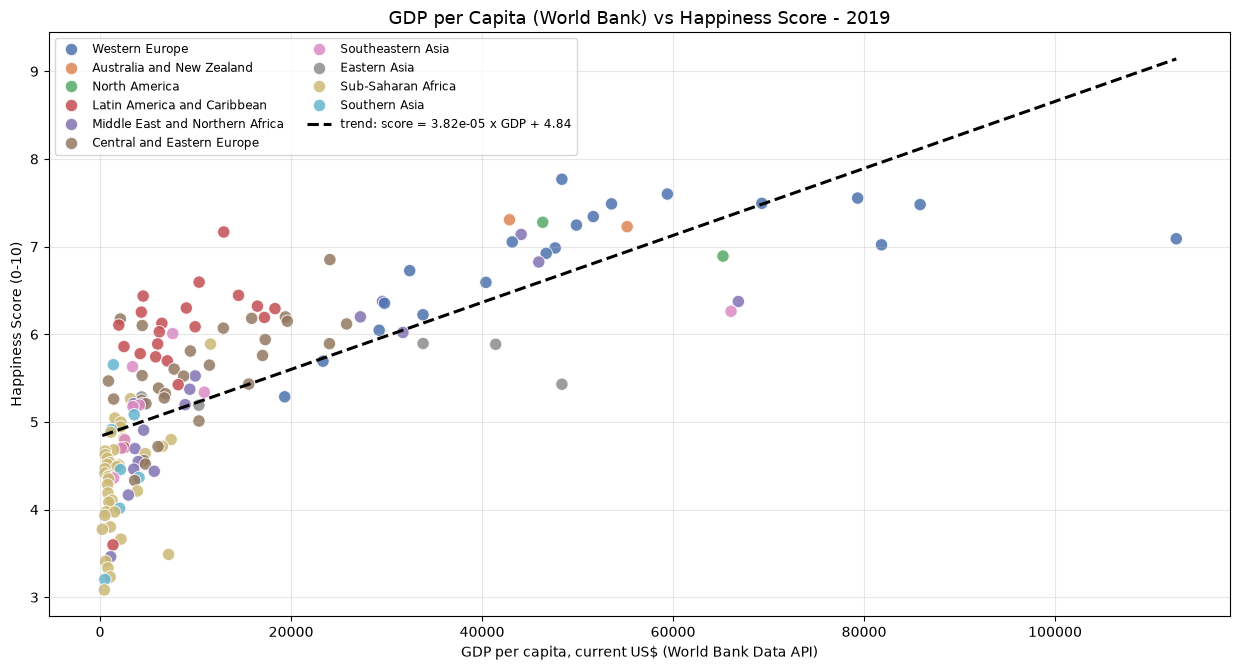

n = 152 countries | Pearson r = 0.74 | Spearman rho = 0.84 | slope = 3.82e-05 | richest point = Luxembourg (112,697 US$, score 7.09)


In [23]:
# Visual 1:
# Visual 1 - 2019: World Bank GDP per capita (x) vs Happiness Score (y), coloured by Region,
# with a linear trend line estimated via numpy.polyfit.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

visual1 = cleaned[cleaned["Year"] == 2019].dropna(
    subset=["wb_gdp_per_capita", "Happiness Score", "Region"])  # need both axes + region color

plt.figure(figsize=(12.5, 6.8))
sns.scatterplot(data=visual1, x="wb_gdp_per_capita", y="Happiness Score", hue="Region",
                s=80, alpha=0.85, palette="deep")

# linear trend line: fit y = slope * x + intercept with numpy.polyfit
slope, intercept = np.polyfit(visual1["wb_gdp_per_capita"], visual1["Happiness Score"], 1)
x_line = np.linspace(visual1["wb_gdp_per_capita"].min(), visual1["wb_gdp_per_capita"].max(), 100)
plt.plot(x_line, slope * x_line + intercept, "k--", linewidth=2.2,
         label=f"trend: score = {slope:.2e} x GDP + {intercept:.2f}")

plt.title("GDP per Capita (World Bank) vs Happiness Score - 2019", fontsize=13)
plt.xlabel("GDP per capita, current US$ (World Bank Data API)")
plt.ylabel("Happiness Score (0-10)")
plt.legend(ncol=2, fontsize=8.5)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# supporting statistics for the written interpretation
pearson = visual1["wb_gdp_per_capita"].corr(visual1["Happiness Score"])
spearman = visual1["wb_gdp_per_capita"].corr(visual1["Happiness Score"], method="spearman")
richest = visual1.loc[visual1["wb_gdp_per_capita"].idxmax()]  # the country at the very right
print(f"n = {len(visual1)} countries | Pearson r = {pearson:.2f} | Spearman rho = {spearman:.2f} | "
      f"slope = {slope:.2e} | richest point = {richest['Country']} "
      f"({richest['wb_gdp_per_capita']:,.0f} US$, score {richest['Happiness Score']:.2f})")

*Answer to research question:* **GDP per capita is a real but decelerating predictor of happiness.** The 2019 scatter (152 countries with World Bank data) climbs as expected: Pearson r = 0.74, Spearman rho = 0.84, and the fitted line gains 3.82e-05 happiness points per dollar, about +0.38 points for each extra $10,000 of GDP per capita. The two ends of the chart differ in kind: below $10,000, 97 countries scatter from 3.08 (Central African Republic) to 6.44 (Guatemala), while above $40,000 the 24 countries bunch between 5.43 (Hong Kong SAR, China) and 7.77 (Finland), with Luxembourg, the richest point at $112,697, sitting at 7.09 rather than at the top of the scale. Region colors explain part of what is left: Finland and Hong Kong SAR, China sit a dollar apart on the x-axis ($48,358 against $48,359) yet differ by 2.34 points (7.77 against 5.43), Costa Rica ($12,952 to 7.17) and Mexico ($10,370 to 6.59) ride well above the fitted line at middle income, and most Sub-Saharan African points sit below it. My answer to the first half of the question is therefore a qualified yes: GDP per capita separates the bottom of the happiness scale from the top, but past roughly $40,000 the points stop climbing.

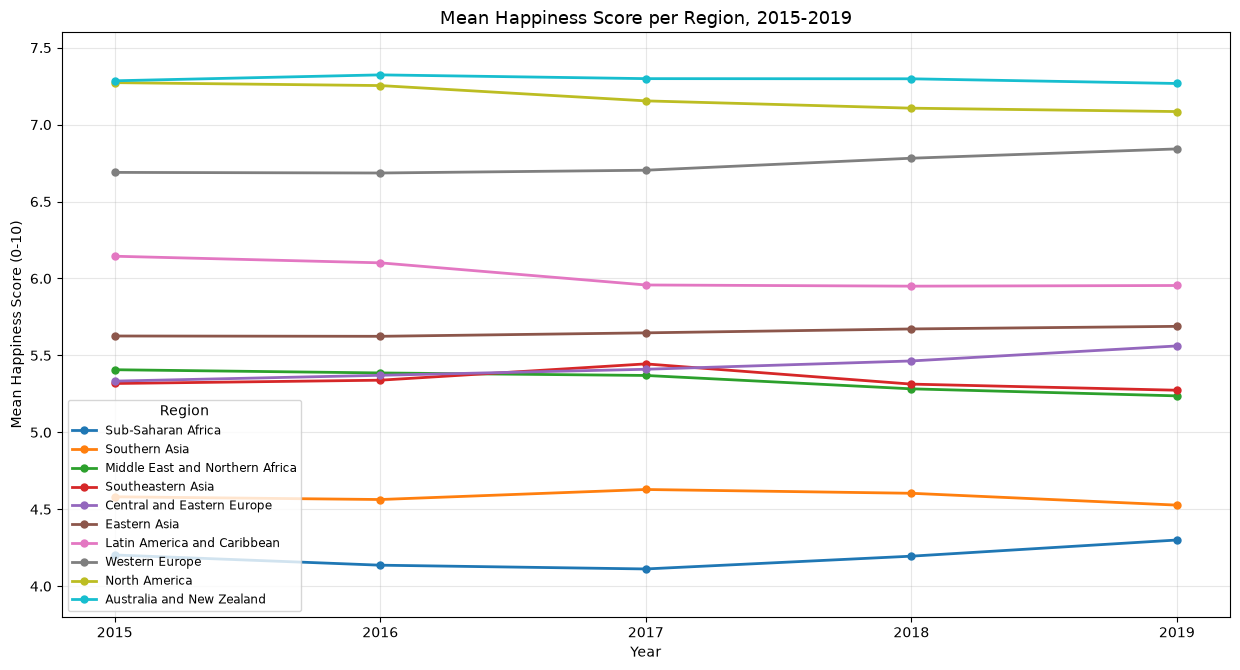

Region
Latin America and Caribbean       -0.190
North America                     -0.188
Middle East and Northern Africa   -0.170
Southern Asia                     -0.054
Southeastern Asia                 -0.044
Australia and New Zealand         -0.018
Eastern Asia                       0.063
Sub-Saharan Africa                 0.097
Western Europe                     0.153
Central and Eastern Europe         0.229
dtype: float64

In [24]:
# Visual 2:
# Visual 2 - mean Happiness Score per Region from 2015 to 2019 (one line per region).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

regional_means = (cleaned.groupby(["Region", "Year"])["Happiness Score"].mean()
                  .unstack("Year"))
regional_means = regional_means.sort_values(2019)  # order the legend by 2019 averages

plt.figure(figsize=(12.5, 6.8))
for region, row in regional_means.iterrows():
    plt.plot(row.index, row.values, marker="o", linewidth=2, markersize=5, label=region)
plt.title("Mean Happiness Score per Region, 2015-2019", fontsize=13)
plt.xlabel("Year")
plt.ylabel("Mean Happiness Score (0-10)")
plt.xticks(HAPPINESS_YEARS)
plt.ylim(3.8, 7.6)
plt.grid(alpha=0.3)
plt.legend(fontsize=8.5, loc="lower left", title="Region")
plt.tight_layout()
plt.show()

# supporting statistics for the written interpretation: change per region 2015 -> 2019
(regional_means[2019] - regional_means[2015]).sort_values().round(3)

*Answer to research question:* **The regional ranking held its shape from 2015 to 2019 while individual regions moved in opposite directions, and the top-to-bottom gap narrowed by only 0.12 points.** Australia and New Zealand (7.27) and North America (7.08) still top the 2019 chart, Sub-Saharan Africa (4.30) and Southern Asia (4.53) still sit at its bottom, and the spread between the highest and lowest region went from 3.09 points in 2015 (7.29 against 4.20) to 2.97 in 2019 (7.27 against 4.30). The individual lines pull apart: Central and Eastern Europe gains the most (+0.229, from 5.33 to 5.56), Western Europe follows (+0.153, 6.69 to 6.84) and Sub-Saharan Africa adds +0.097 (4.20 to 4.30), while Latin America and Caribbean drops 0.190 (6.14 to 5.95), North America drops 0.188 (7.27 to 7.08) and Middle East and Northern Africa drops 0.170 (5.41 to 5.24). Income alone does not sort those movements: rich Western Europe gained while rich North America fell, and middle-income Central and Eastern Europe gained while middle-income Latin America fell. Region therefore keeps its own offset on top of GDP from one end of the period to the other, and because these lines are descriptive means, the deltas tell me what moved, not why (conflict, policy and survey effects all sit uncontrolled in these numbers).

### **5.2:** Reflection
In 2-4 sentences, if you had more time to complete the project, what actions would you take? For example, which data quality and structural issues would you look into further, and what research questions would you further explore?

**Reflection:** Seventeen merged rows still carry no GDP figure, and with more time I would pull them from the IMF WEO API so the scatter stops resting on 97.8% coverage. South Sudan has no World Bank figure for 2016-2019, Yemen none for 2019, and Taiwan (both spellings), the two Cyprus spellings and the two Somaliland spellings are not separate World Bank economies at all, which accounts for the other twelve rows. The country-name step is the other soft spot: a 26-entry dictionary plus a 0.75 fuzzy cutoff leaves six names I am matching by hand, so I would fetch ISO-3 codes from the World Bank's country metadata and join on those instead, then audit every name the dictionary touched at least once. I would also stop fitting the relationship as a straight line, using log GDP or a piecewise trend to capture the flattening above $40,000, and pit GDP per capita against `Social support` and `Health (Life Expectancy)`, which are already clean in the same table, to see which one actually carries the 0.74 correlation of 2019.